In [10]:
# %% [markdown]
# # Superconducting memory energy trend
#
# This notebook plots representative cold-stage superconducting-memory energies.
# Read/access energy and write energy are shown on the same plot.
#
# Notes:
# - Historical Josephson RAM papers often report only access energy, not separate read/write.
# - Some modern values are estimates rather than directly reported array-level numbers.
# - The plot is therefore an order-of-magnitude comparison, not a strict scaling law.

# %%
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# %%
# -----------------------------
# Helper functions
# -----------------------------
def geometric_mean(low, high):
    if pd.isna(low) or pd.isna(high):
        return np.nan
    return np.sqrt(low * high)

def asym_err(center, low, high):
    """
    Return asymmetric y-errors for matplotlib errorbar.
    """
    if pd.isna(center) or pd.isna(low) or pd.isna(high):
        return np.array([[0.0], [0.0]])
    return np.array([[center - low], [high - center]])

# %%
# -----------------------------
# Data
# -----------------------------
# Energies are in joules.
# For historical Josephson RAMs, "read/access" is really an access-energy estimate.
# For devices where only a range is available, we plot the geometric mean.

data = [
    {
        "year": 1979,
        "device": "IBM Josephson memory projection",
        "label": "IBM proj.",
        "category": "Historical Josephson RAM",
        "read_low_J": 3.0e-12,
        "read_high_J": 3.0e-12,
        "write_low_J": np.nan,
        "write_high_J": np.nan,
        "note": "Estimated access energy from 6 mW × 0.5 ns"
    },
    {
        "year": 1989,
        "device": "Josephson 1-kbit NDRO RAM",
        "label": "1-kbit NDRO",
        "category": "Historical Josephson RAM",
        "read_low_J": 7.4e-12,
        "read_high_J": 7.4e-12,
        "write_low_J": np.nan,
        "write_high_J": np.nan,
        "note": "Estimated access energy from 13 mW × 570 ps"
    },
    {
        "year": 1991,
        "device": "4K×1-bit Josephson RAM",
        "label": "4K×1 RAM",
        "category": "Historical Josephson RAM",
        "read_low_J": 11.0e-12,
        "read_high_J": 11.0e-12,
        "write_low_J": np.nan,
        "write_high_J": np.nan,
        "note": "Estimated access energy from 19 mW × 590 ps"
    },
    {
        "year": 1995,
        "device": "Josephson 4-kbit RAM",
        "label": "4-kbit RAM",
        "category": "Historical Josephson RAM",
        "read_low_J": 3.6e-12,
        "read_high_J": 3.6e-12,
        "write_low_J": np.nan,
        "write_high_J": np.nan,
        "note": "Estimated access energy from 9.5 mW × 380 ps"
    },
    {
        "year": 2013,
        "device": "Hybrid Josephson-CMOS 64-kb RAM",
        "label": "J-CMOS 64 kb",
        "category": "Hybrid Josephson-CMOS",
        "read_low_J": 4.8e-12,
        "read_high_J": 4.8e-12,
        "write_low_J": np.nan,
        "write_high_J": np.nan,
        "note": "Estimated read energy from 12 mW × 400 ps"
    },
    {
        "year": 2014,
        "device": "Baek magnetic Josephson memory",
        "label": "Baek MJJ",
        "category": "Magnetic Josephson memory",
        "read_low_J": 1e-18,
        "read_high_J": 1e-15,
        "write_low_J": 1e-14,
        "write_high_J": 1e-11,
        "note": "Read estimated from Ic Phi0; write from I^2 R tau"
    },
    {
        "year": 2018,
        "device": "Dayton 0/pi JMRAM cell",
        "label": "Dayton 0/π",
        "category": "Magnetic Josephson memory",
        "read_low_J": 1e-18,
        "read_high_J": 1e-15,
        "write_low_J": 6e-14,
        "write_high_J": 6e-12,
        "note": "Read estimated from Josephson/SQUID scale; write from magnetic write line"
    },
    {
        "year": 2024,
        "device": "Josephson vortex memory",
        "label": "J-vortex",
        "category": "Josephson vortex memory",
        "read_low_J": 1e-18,
        "read_high_J": 1e-15,
        "write_low_J": np.nan,        # safer: not directly reported
        "write_high_J": np.nan,       # projected values omitted here
        "note": "Read estimated from microwave power × integration time"
    },
    {
        "year": 2025,
        "device": "Berggren nanowire memory array",
        "label": "Berggren NW",
        "category": "Nanowire memory",
        "read_low_J": 0.20e-12,
        "read_high_J": 0.23e-12,
        "write_low_J": 1.2e-12,
        "write_high_J": 1.3e-12,
        "note": "Reported total read/write energy including enable-line overhead"
    },
    {
        "year": 2026,
        "device": "Moodera EuS/V/EuS exchange memory",
        "label": "Moodera EuS/V/EuS",
        "category": "Exchange-coupled memory",
        "read_low_J": 1e-19,
        "read_high_J": 1e-18,
        "write_low_J": 0.64e-3,
        "write_high_J": 6.4e-3,
        "note": "Read projected from SFQ-compatible scale; write estimated from I^2 R tau"
    },
]

df = pd.DataFrame(data)

# Representative plotted values
df["read_J"] = [geometric_mean(l, h) for l, h in zip(df["read_low_J"], df["read_high_J"])]
df["write_J"] = [geometric_mean(l, h) for l, h in zip(df["write_low_J"], df["write_high_J"])]

df

,year,device,label,category,read_low_J,read_high_J,write_low_J,write_high_J,note,read_J,write_J
0,1979,IBM Josephson memory projection,IBM proj.,Historical Josephson RAM,3.000000e-12,3.000000e-12,NaN,NaN,Estimated access energy from 6 mW × 0.5 ns,3.000000e-12,NaN
1,1989,Josephson 1-kbit NDRO RAM,1-kbit NDRO,Historical Josephson RAM,7.400000e-12,7.400000e-12,NaN,NaN,Estimated access energy from 13 mW × 570 ps,7.400000e-12,NaN
2,1991,4K×1-bit Josephson RAM,4K×1 RAM,Historical Josephson RAM,1.100000e-11,1.100000e-11,NaN,NaN,Estimated access energy from 19 mW × 590 ps,1.100000e-11,NaN
3,1995,Josephson 4-kbit RAM,4-kbit RAM,Historical Josephson RAM,3.600000e-12,3.600000e-12,NaN,NaN,Estimated access energy from 9.5 mW × 380 ps,3.600000e-12,NaN
4,2013,Hybrid Josephson-CMOS 64-kb RAM,J-CMOS 64 kb,Hybrid Josephson-CMOS,4.800000e-12,4.800000e-12,NaN,NaN,Estimated read energy from 12 mW × 400 ps,4.800000e-12,NaN
5,2014,Baek magnetic Josephson memory,Baek MJJ,Magnetic Josephson memory,1.000000e-18,1.000000e-15,1.000000e-14,1.000000e-11,Read estimated from Ic Phi0; write from I^2 R tau,3.162278e-17,3.162278e-13
6,2018,Dayton 0/pi JMRAM cell,Dayton 0/π,Magnetic Josephson memory,1.000000e-18,1.000000e-15,6.000000e-14,6.000000e-12,Read estimated from Josephson/SQUID scale; wri...,3.162278e-17,6.000000e-13
7,2024,Josephson vortex memory,J-vortex,Josephson vortex memory,1.000000e-18,1.000000e-15,NaN,NaN,Read estimated from microwave power × integrat...,3.162278e-17,NaN
8,2025,Berggren nanowire memory array,Berggren NW,Nanowire memory,2.000000e-13,2.300000e-13,1.200000e-12,1.300000e-12,Reported total read/write energy including ena...,2.144761e-13,1.249000e-12
9,2026,Moodera EuS/V/EuS exchange memory,Moodera EuS/V/EuS,Exchange-coupled memory,1.000000e-19,1.000000e-18,6.400000e-04,6.400000e-03,Read projected from SFQ-compatible scale; writ...,3.162278e-19,2.023858e-03


In [11]:
# %% [markdown]
# ## Quick check of the plotting table

# %%
display_cols = [
    "year", "label", "device", "read_low_J", "read_high_J", "read_J",
    "write_low_J", "write_high_J", "write_J", "note"
]
display(df[display_cols])

,year,label,device,read_low_J,read_high_J,read_J,write_low_J,write_high_J,write_J,note
0,1979,IBM proj.,IBM Josephson memory projection,3.000000e-12,3.000000e-12,3.000000e-12,NaN,NaN,NaN,Estimated access energy from 6 mW × 0.5 ns
1,1989,1-kbit NDRO,Josephson 1-kbit NDRO RAM,7.400000e-12,7.400000e-12,7.400000e-12,NaN,NaN,NaN,Estimated access energy from 13 mW × 570 ps
2,1991,4K×1 RAM,4K×1-bit Josephson RAM,1.100000e-11,1.100000e-11,1.100000e-11,NaN,NaN,NaN,Estimated access energy from 19 mW × 590 ps
3,1995,4-kbit RAM,Josephson 4-kbit RAM,3.600000e-12,3.600000e-12,3.600000e-12,NaN,NaN,NaN,Estimated access energy from 9.5 mW × 380 ps
4,2013,J-CMOS 64 kb,Hybrid Josephson-CMOS 64-kb RAM,4.800000e-12,4.800000e-12,4.800000e-12,NaN,NaN,NaN,Estimated read energy from 12 mW × 400 ps
5,2014,Baek MJJ,Baek magnetic Josephson memory,1.000000e-18,1.000000e-15,3.162278e-17,1.000000e-14,1.000000e-11,3.162278e-13,Read estimated from Ic Phi0; write from I^2 R tau
6,2018,Dayton 0/π,Dayton 0/pi JMRAM cell,1.000000e-18,1.000000e-15,3.162278e-17,6.000000e-14,6.000000e-12,6.000000e-13,Read estimated from Josephson/SQUID scale; wri...
7,2024,J-vortex,Josephson vortex memory,1.000000e-18,1.000000e-15,3.162278e-17,NaN,NaN,NaN,Read estimated from microwave power × integrat...
8,2025,Berggren NW,Berggren nanowire memory array,2.000000e-13,2.300000e-13,2.144761e-13,1.200000e-12,1.300000e-12,1.249000e-12,Reported total read/write energy including ena...
9,2026,Moodera EuS/V/EuS,Moodera EuS/V/EuS exchange memory,1.000000e-19,1.000000e-18,3.162278e-19,6.400000e-04,6.400000e-03,2.023858e-03,Read projected from SFQ-compatible scale; writ...


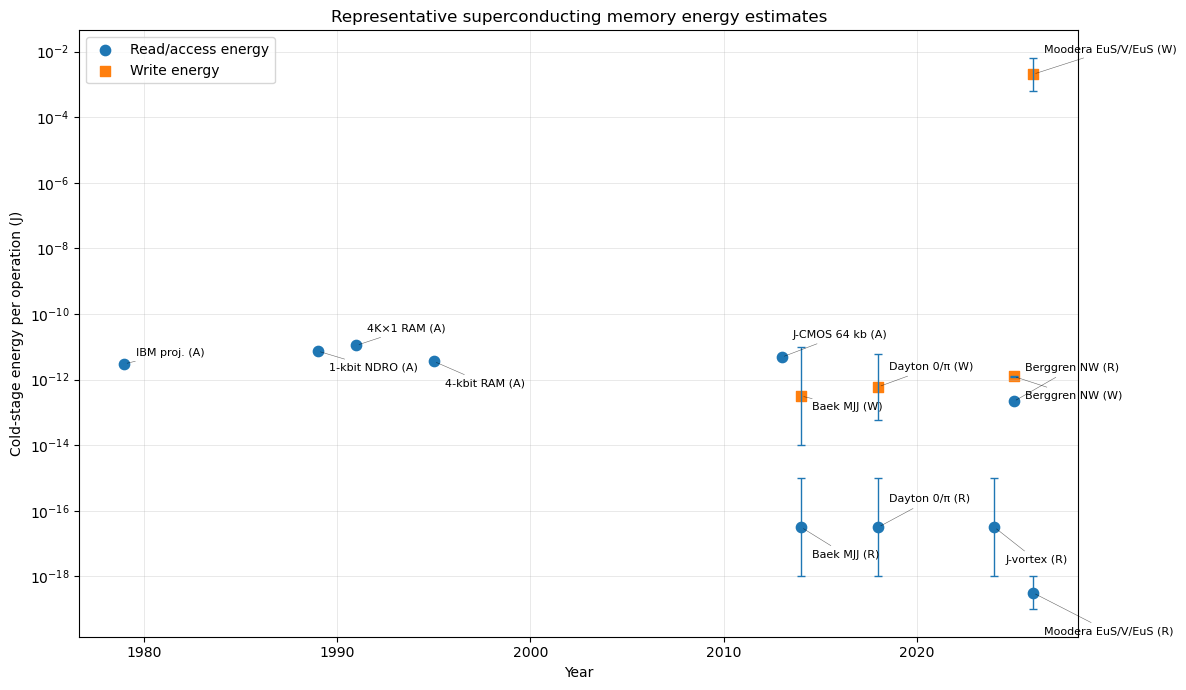

In [12]:
# %% [markdown]
# ## Combined read/access + write energy plot
#
# Labeling convention:
# - (A) = access energy for historical RAM points
# - (R) = read energy
# - (W) = write energy

# %%
fig, ax = plt.subplots(figsize=(12, 7))

read_df = df.dropna(subset=["read_J"]).copy()
write_df = df.dropna(subset=["write_J"]).copy()

# Plot read/access points
ax.scatter(
    read_df["year"],
    read_df["read_J"],
    marker="o",
    s=55,
    label="Read/access energy"
)

# Plot read/access error bars
for _, row in read_df.iterrows():
    yerr = asym_err(row["read_J"], row["read_low_J"], row["read_high_J"])
    ax.errorbar(
        row["year"],
        row["read_J"],
        yerr=yerr,
        fmt="none",
        capsize=3,
        linewidth=1
    )

# Plot write points
ax.scatter(
    write_df["year"],
    write_df["write_J"],
    marker="s",
    s=55,
    label="Write energy"
)

# Plot write error bars
for _, row in write_df.iterrows():
    yerr = asym_err(row["write_J"], row["write_low_J"], row["write_high_J"])
    ax.errorbar(
        row["year"],
        row["write_J"],
        yerr=yerr,
        fmt="none",
        capsize=3,
        linewidth=1
    )

# %%
# Annotate every read/access point
read_offsets = [
    (8, 8), (8, -12), (8, 12), (8, -16), (8, 16),
    (8, -20), (8, 20), (8, -24), (8, 24), (8, -28)
]

for i, (_, row) in enumerate(read_df.iterrows()):
    dx, dy = read_offsets[i % len(read_offsets)]

    # Historical RAMs are access energies, not separated read energies
    if row["category"] == "Historical Josephson RAM" or row["category"] == "Hybrid Josephson-CMOS":
        tag = "(A)"
    else:
        tag = "(R)"

    ax.annotate(
        f"{row['label']} {tag}",
        (row["year"], row["read_J"]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=8,
        ha="left",
        va="center",
        arrowprops=dict(arrowstyle="-", linewidth=0.4, alpha=0.6)
    )

# Annotate every write point
write_offsets = [
    (8, -8), (8, 14), (8, -14), (8, 18), (8, -18),
    (8, 22), (8, -22), (8, 26), (8, -26), (8, 30)
]

for i, (_, row) in enumerate(write_df.iterrows()):
    dx, dy = write_offsets[i % len(write_offsets)]

    ax.annotate(
        f"{row['label']} (W)",
        (row["year"], row["write_J"]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=8,
        ha="left",
        va="center",
        arrowprops=dict(arrowstyle="-", linewidth=0.4, alpha=0.6)
    )

# %%
ax.set_yscale("log")
ax.set_xlabel("Year")
ax.set_ylabel("Cold-stage energy per operation (J)")
ax.set_title("Representative superconducting memory energy estimates")
ax.grid(True, which="both", linewidth=0.5, alpha=0.4)
ax.legend()

plt.tight_layout()
plt.savefig("superconducting_memory_read_write_energy.png", dpi=300, bbox_inches="tight")
plt.show()

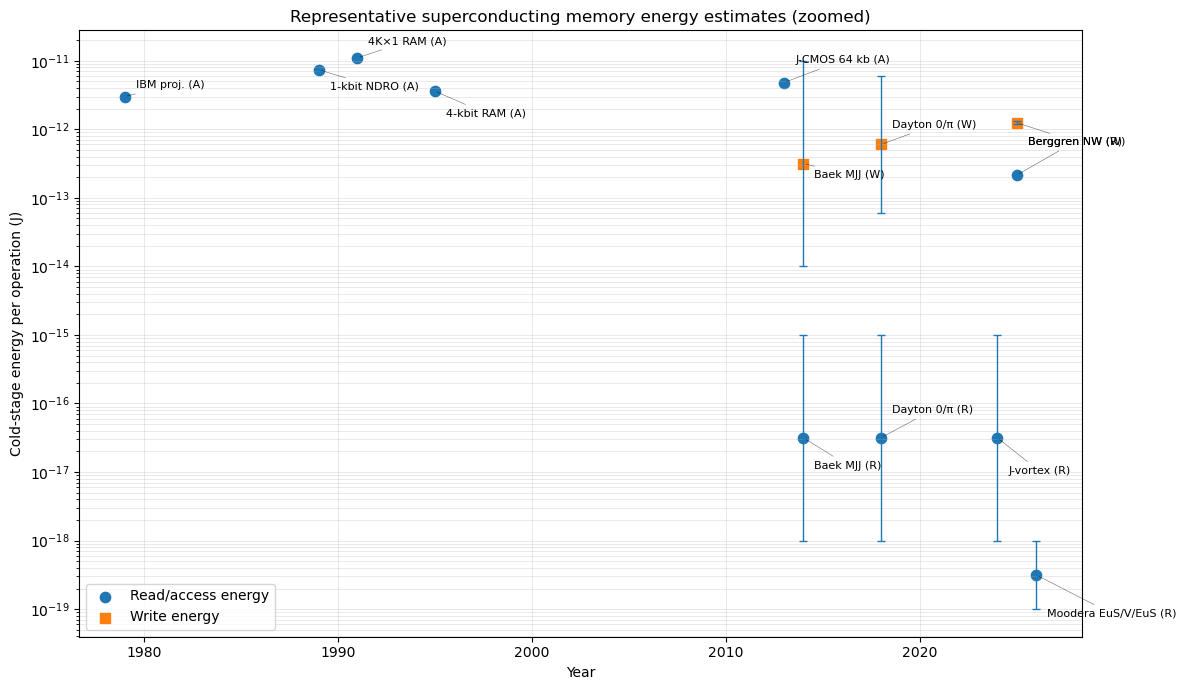

In [13]:
# %% [markdown]
# ## Optional: zoomed plot without the large Moodera write-energy point
#
# This makes the low-energy region easier to see.

# %%
df_zoom = df.copy()
mask = df_zoom["label"] == "Moodera EuS/V/EuS"
df_zoom.loc[mask, ["write_low_J", "write_high_J", "write_J"]] = np.nan

read_df = df_zoom.dropna(subset=["read_J"]).copy()
write_df = df_zoom.dropna(subset=["write_J"]).copy()

fig, ax = plt.subplots(figsize=(12, 7))

# Read/access
ax.scatter(read_df["year"], read_df["read_J"], marker="o", s=55, label="Read/access energy")
for _, row in read_df.iterrows():
    yerr = asym_err(row["read_J"], row["read_low_J"], row["read_high_J"])
    ax.errorbar(row["year"], row["read_J"], yerr=yerr, fmt="none", capsize=3, linewidth=1)

# Write
ax.scatter(write_df["year"], write_df["write_J"], marker="s", s=55, label="Write energy")
for _, row in write_df.iterrows():
    yerr = asym_err(row["write_J"], row["write_low_J"], row["write_high_J"])
    ax.errorbar(row["year"], row["write_J"], yerr=yerr, fmt="none", capsize=3, linewidth=1)

# Labels
for i, (_, row) in enumerate(read_df.iterrows()):
    dx, dy = read_offsets[i % len(read_offsets)]
    if row["category"] == "Historical Josephson RAM" or row["category"] == "Hybrid Josephson-CMOS":
        tag = "(A)"
    else:
        tag = "(R)"
    ax.annotate(
        f"{row['label']} {tag}",
        (row["year"], row["read_J"]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=8,
        ha="left",
        va="center",
        arrowprops=dict(arrowstyle="-", linewidth=0.4, alpha=0.6)
    )

for i, (_, row) in enumerate(write_df.iterrows()):
    dx, dy = write_offsets[i % len(write_offsets)]
    ax.annotate(
        f"{row['label']} (W)",
        (row["year"], row["write_J"]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=8,
        ha="left",
        va="center",
        arrowprops=dict(arrowstyle="-", linewidth=0.4, alpha=0.6)
    )

ax.set_yscale("log")
ax.set_xlabel("Year")
ax.set_ylabel("Cold-stage energy per operation (J)")
ax.set_title("Representative superconducting memory energy estimates (zoomed)")
ax.grid(True, which="both", linewidth=0.5, alpha=0.4)
ax.legend()

plt.tight_layout()
plt.savefig("superconducting_memory_read_write_energy_zoom.png", dpi=300, bbox_inches="tight")
plt.show()